# Metamorph: demo

A guided tour of the package, from the forward model to counterfactual design.
This notebook reuses the posterior saved by `scripts/phase3_calibration.py`
(`results/phase3_posterior.nc`), so it runs in a few minutes; the phase scripts
in `scripts/` are the reference for every number quoted in the README.

Run from the `notebooks/` folder after `pip install -e .` and
`python scripts/run_all.py`.

In [1]:
from pathlib import Path

import arviz as az
import matplotlib.pyplot as plt
import numpy as np

import metamorph  # enables float64 in JAX
from metamorph.model import TRUE_PARAMS, PARAM_NAMES, simulate, compartment_totals
from metamorph.plotting import plot_trajectories

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

## 1. Forward model

An IV bolus of 100 %ID of bare particles. In blood, particles become coated at
rate `k_coat`; tissues take up bare and coated particles at different rates.

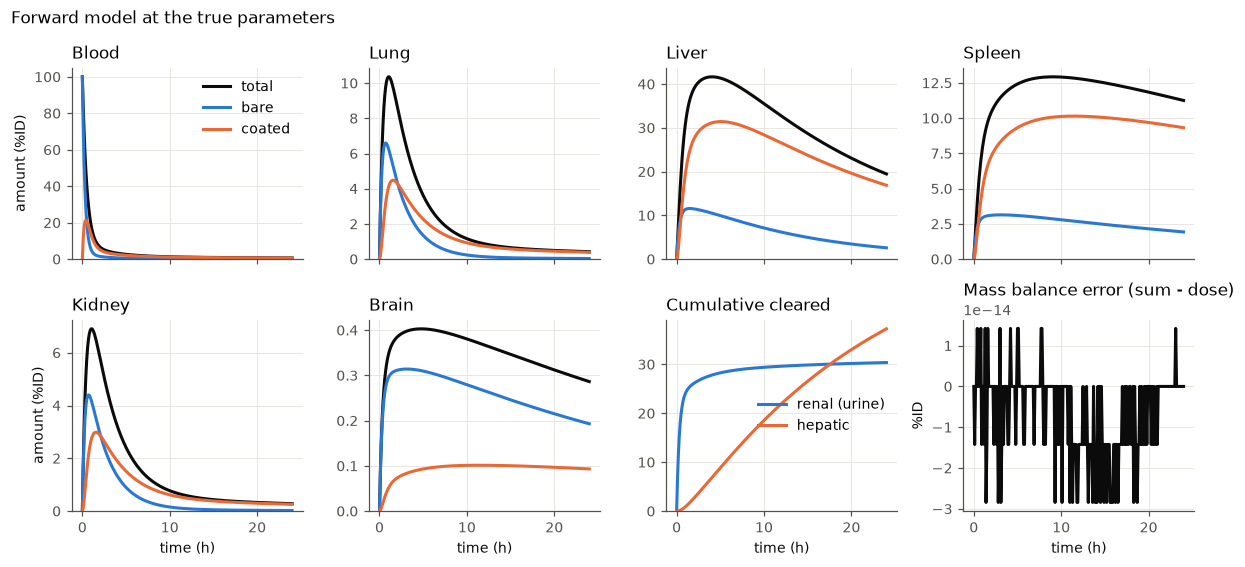

max |total mass - 100| = 2.8e-14 %ID


In [2]:
ts = np.linspace(0.0, 24.0, 241)
ys = np.asarray(simulate(TRUE_PARAMS, ts))
fig = plot_trajectories(ts, ys, title="Forward model at the true parameters")
plt.show()
print(f"max |total mass - 100| = {np.abs(ys.sum(axis=1) - 100).max():.1e} %ID")

## 2. Synthetic data

Totals (bare + coated) in blood and urine at 7 times, in tissues at 3 times,
3 replicates, multiplicative log-normal noise.

In [3]:
from metamorph.data import OBSERVABLES, load_dataset

dataset = load_dataset(ROOT / "data")
print(len(dataset), "measurements")
for name in OBSERVABLES:
    rows = dataset.observable == name
    print(f"  {name:7s} times (h): {np.unique(np.round(dataset.time[rows], 3))}")

87 measurements
  blood   times (h): [ 0.083  0.25   0.5    1.     4.     8.    24.   ]
  lung    times (h): [ 1.  4. 24.]
  liver   times (h): [ 1.  4. 24.]
  spleen  times (h): [ 1.  4. 24.]
  kidney  times (h): [ 1.  4. 24.]
  brain   times (h): [ 1.  4. 24.]
  urine   times (h): [ 0.083  0.25   0.5    1.     4.     8.    24.   ]


## 3. Posterior (NUTS, 4 chains)

Diagnostics and the comparison with the true values.

In [4]:
from metamorph.inference import parameter_table

idata = az.from_netcdf(ROOT / "results" / "phase3_posterior.nc")
print("divergences:", int(idata.sample_stats["diverging"].values.sum()))
truth = dict(TRUE_PARAMS, sigma=0.2)
print(f"{'parameter':12s} {'true':>8s} {'mean':>8s} {'90% CI':>22s} {'R-hat':>6s}")
for r in parameter_table(idata, truth):
    ci = f"[{r['lower']:.3g}, {r['upper']:.3g}]"
    print(f"{r['name']:12s} {r['true']:8.3g} {r['mean']:8.3g} {ci:>22s} {r['r_hat']:6.3f}")

E:\Metamorph\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


divergences: 0
parameter        true     mean                 90% CI  R-hat


k_coat            1.5     1.92           [1.39, 2.51]  1.000
CL_renal          0.8    0.921          [0.785, 1.07]  1.000
CL_liver         0.05   0.0529       [0.0438, 0.0625]  1.000
k_in_lung         0.3    0.256         [0.207, 0.313]  1.000
k_in_liver        0.4    0.338          [0.177, 0.54]  1.000
k_in_spleen       0.1    0.087         [0.045, 0.139]  1.000
k_in_kidney       0.2    0.166         [0.134, 0.205]  1.000
k_in_brain       0.01   0.0118       [0.0085, 0.0153]  1.000
m_RES               3      4.1            [1.99, 7.5]  1.000
m_brain           0.3    0.373         [0.131, 0.775]  1.000
k_out_fast        0.5    0.434          [0.35, 0.535]  1.000
k_out_slow       0.03   0.0349       [0.0273, 0.0437]  1.000
sigma             0.2    0.196         [0.171, 0.224]  1.000


## 4. Posterior predictive check (brain and urine)

200 posterior draws, noiseless model curves, against the data.

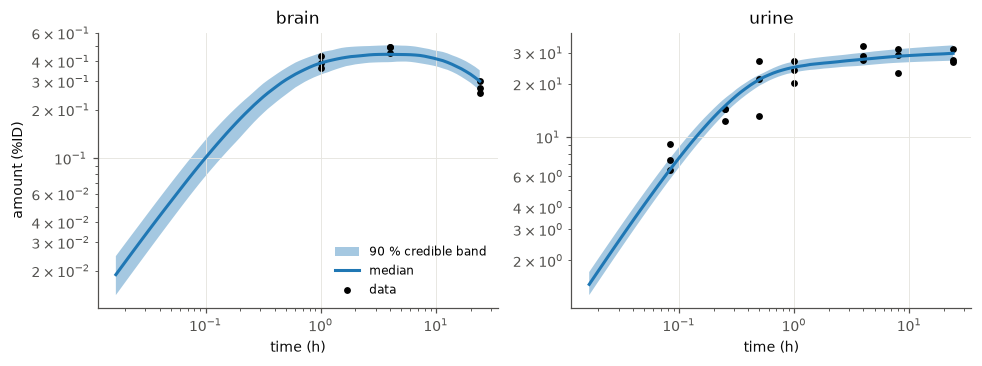

In [5]:
from metamorph.inference import predict_observables

draws = {n: idata.posterior[n].values.ravel()[::20] for n in PARAM_NAMES}
t_plot = np.geomspace(1 / 60, 24, 80)
pred = predict_observables(draws, t_plot)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, name in zip(axes, ["brain", "urine"]):
    k = OBSERVABLES.index(name)
    lo, med, hi = np.quantile(pred[:, :, k], [0.05, 0.5, 0.95], axis=0)
    ax.fill_between(t_plot, lo, hi, alpha=0.4, label="90 % credible band")
    ax.plot(t_plot, med, label="median")
    rows = dataset.observable == name
    ax.scatter(dataset.time[rows], dataset.value[rows], color="k", s=12, label="data")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(name); ax.set_xlabel("time (h)")
axes[0].set_ylabel("amount (%ID)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Counterfactual design

Smallest change of diameter `d` and coating propensity `h` that brings the
brain amount at 24 h below 0.2 %ID, first at the posterior mean, then with
P(success) >= 0.9. Same draw split as `scripts/phase5_counterfactual.py`
(1000 draws for optimization, 3000 held out), but a coarser grid for the
starting point, so the result may differ slightly from the phase 5 script.

In [6]:
from metamorph.counterfactual import (
    THRESHOLD, best_grid_point, brain_over_draws, evaluate_grid,
    point_counterfactual, robust_counterfactual,
)

all_draws = {n: idata.posterior[n].values.ravel() for n in PARAM_NAMES}
perm = np.random.default_rng(0).permutation(len(all_draws["k_coat"]))
opt = {n: v[perm[:1000]] for n, v in all_draws.items()}
held_out = {n: v[perm[1000:]] for n, v in all_draws.items()}
point = {n: float(v.mean()) for n, v in all_draws.items()}

u_grid, v_grid = np.linspace(-1, 5, 21), np.linspace(-3, 3, 21)
grid = evaluate_grid(opt, u_grid, v_grid)
grid_point = evaluate_grid({n: np.array([point[n]]) for n in PARAM_NAMES}, u_grid, v_grid)[..., 0]

cf_point = point_counterfactual(point, best_grid_point(grid_point <= THRESHOLD, u_grid, v_grid))
cf_robust = robust_counterfactual(opt, best_grid_point(np.quantile(grid, 0.9, axis=-1) <= THRESHOLD, u_grid, v_grid))

for name, cf in [("point estimate", cf_point), ("robust", cf_robust)]:
    p = np.mean(brain_over_draws(held_out, cf.d, cf.h) <= THRESHOLD)
    print(f"{name:15s} d = {cf.d:.2f} nm, h = {cf.h:.2f}, distance = {cf.distance:.2f}, "
          f"P(success, held-out) = {p:.3f}")

point estimate  d = 6.87 nm, h = 1.57, distance = 1.14, P(success, held-out) = 0.441
robust          d = 7.96 nm, h = 1.45, distance = 1.57, P(success, held-out) = 0.892


The point-estimate design sits on the threshold for one parameter value and
fails for more than half of the plausible ones. The robust design moves
further, mainly along the diameter, which acts through well-identified
parameters.